# PR1 — Differential abundance and enrichment analysis

**27200 Data-driven Bioengineering · group project, PR1 (heart valve disease)**

This notebook starts where our processing and QC notebook stopped. It reads the processed data
(`PR1_processed_data.xlsx`) and answers one question:

> **Which proteins change in the left ventricle of patients with aortic stenosis (AS) compared with
> donor hearts (controls), and what do those proteins do?**

It has two parts:

| Part | What | Why |
|---|---|---|
| **A · Statistics** | One Mann–Whitney test per protein, Benjamini–Hochberg correction, fold changes, a hit list | Enrichment needs a list of changed proteins. The processing notebook did not test anything yet. |
| **B · Enrichment** | g:Profiler (GO terms, Reactome, KEGG) and the Reactome analysis service | Turns a list of hundreds of proteins into a statement about biological functions |

Part B follows the in-class Week 7 notebook (`02_downstream_analysis`, sections B3 and B4) step by
step. The only differences are that we run the **up**- and the **down**-regulated proteins separately
(the class notebook left the down-regulated ones as Question 2.8), and that we save the results to
files.

**Before you run it**

- Put `PR1_processed_data.xlsx` in the same folder as this notebook (or in a subfolder called `data`).
- Packages: `pandas numpy scipy matplotlib openpyxl requests gprofiler-official`.
- Part B needs an internet connection: g:Profiler and Reactome are web services.

---
# Part A · From processed data to a list of changed proteins

## A0 · Settings

All the choices that change the result are collected in one place, so you can see them and change
them without hunting through the code. If you change one, rerun the whole notebook.

| Setting | Meaning |
|---|---|
| `CASE`, `CONTROL` | the two groups we compare |
| `Q_CUT` | a protein counts as significant if its Benjamini–Hochberg q-value is below this |
| `FC_CUT` | ...and if it changes at least this many fold (1.5-fold = a log2 fold change above 0.58) |
| `MIN_VALID_BOTH` | ...and if it was really measured (not imputed) in at least this fraction of **both** groups |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- SETTINGS ----
CASE, CONTROL  = "aortic stenosis", "control (donor heart)"   # disease group vs reference group
Q_CUT          = 0.05     # Benjamini-Hochberg q-value cutoff
FC_CUT         = 1.5      # minimum fold change (1.5-fold = |log2FC| > 0.58)
MIN_VALID_BOTH = 0.50     # protein must have real values in >= 50 % of BOTH groups to enter the main hit list
OUT_DIR        = "results"  # all tables and figures are saved here

os.makedirs(OUT_DIR, exist_ok=True)
print("ready")

ready


## A1 · Load the processed data

The Excel file from the processing notebook has four sheets. We use three of them:

| Sheet | Content | Used for |
|---|---|---|
| `not_imputed` | log2, median-normalised intensities; missing values left empty (NaN) | fold changes, and checking how many **real** values a protein has |
| `imputed` | the same table with missing values filled in (Perseus method) | the statistical test, which needs a complete table |
| `sample_qc` | one row per sample: group, sex and the QC flags | knowing which column belongs to which group |

Each data sheet has one row per protein group: first 14 annotation columns (protein IDs, gene names,
number of peptides...), then one column per sample (`CON_01_M`, `AS_01_M`, ...).

In [2]:
def find(name):
    '''Look for a file next to the notebook or in a data/ folder.'''
    for folder in [".", "data", "../data"]:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"Put {name} next to this notebook or in a folder called data/")

XLSX = find("PR1_processed_data.xlsx")
not_imp = pd.read_excel(XLSX, sheet_name="not_imputed")    # real values only, NaN = missing
imp     = pd.read_excel(XLSX, sheet_name="imputed")        # complete table
qc      = pd.read_excel(XLSX, sheet_name="sample_qc")      # group and sex per sample

print(f"{len(not_imp)} proteins x {len(qc)} samples")
print(qc.groupby(["group", "sex"]).size().unstack().to_string())

3834 proteins x 75 samples
sex                    female  male
group                              
aortic stenosis            21    20
control (donor heart)       8     9
mitral regurgitation        5    12


## A2 · Define the two groups and get one gene symbol per protein

**Groups.** The sample sheet says which sample belongs to which group, so we take the column names
from there instead of guessing them from the names. The mitral regurgitation samples are not used in
this comparison.

**Gene symbols.** Enrichment tools work with gene symbols (`COL3A1`, `PDK4`...), one per protein. The
`Gene names` column sometimes holds several symbols separated by `;`, because MaxQuant reports a
*protein group*: all proteins that share the detected peptides (the protein inference problem from the
Week 7 lecture). We keep the **first** symbol, which belongs to the leading protein of the group.
Proteins without a gene name get an empty string and are left out of the enrichment later.

In [3]:
case = qc.loc[qc.group == CASE, "sample"].tolist()        # the 41 aortic stenosis samples
ctl  = qc.loc[qc.group == CONTROL, "sample"].tolist()     # the 17 donor-heart controls
print(f"{CASE}: {len(case)} samples | {CONTROL}: {len(ctl)} samples")

genes = not_imp["Gene names"].fillna("").astype(str).str.split(";").str[0]   # first symbol only
print(f"{(not_imp['Gene names'].fillna('').str.contains(';')).sum()} protein groups had several gene names "
      f"-> kept the first; {(genes == '').sum()} have no gene name")

aortic stenosis: 41 samples | control (donor heart): 17 samples
281 protein groups had several gene names -> kept the first; 1 have no gene name


## A3 · How many real values does each protein have in each group?

The processing notebook kept a protein if it was measured in at least 60 % of **any one** group. That
means some proteins are measured well in controls but are mostly missing in AS (or the other way
round). In the imputed table their missing values were filled with low random numbers.

Why that matters: a rank test puts those imputed low values at the bottom of the ranking, so such a
protein comes out "significant" almost automatically, and its fold change is partly invented. We
therefore record, for every protein, the fraction of **real** values in each group. The next steps use
it to keep these proteins out of the main hit list and report them separately.

In [4]:
valid_case = not_imp[case].notna().mean(axis=1)     # fraction of AS samples with a real value
valid_ctl  = not_imp[ctl].notna().mean(axis=1)      # fraction of control samples with a real value
both_ok = (valid_case >= MIN_VALID_BOTH) & (valid_ctl >= MIN_VALID_BOTH)

print(f"measured in >= {MIN_VALID_BOTH:.0%} of both groups: {both_ok.sum()} proteins")
print(f"measured mostly in one group only: {(~both_ok).sum()} proteins")

measured in >= 50% of both groups: 3514 proteins
measured mostly in one group only: 320 proteins


## A4 · Test every protein: Mann–Whitney U test

For each protein we ask: are the values in AS systematically higher or lower than in controls?

We use the **Mann–Whitney U test** (also called the Wilcoxon rank-sum test), as the group decided in
the processing notebook (section 15), because a substantial share of proteins was not normally
distributed within the groups. The test does not use the values themselves. It puts all 58 samples in
order from lowest to highest and asks whether the AS samples tend to sit higher (or lower) in that
order than you would expect by chance. It makes no assumption about the shape of the distribution.

The test needs a value for every sample, so it runs on the **imputed** table.

What the test does **not** give you is a fold change, so we calculate that separately in A5.

In [5]:
mw = stats.mannwhitneyu(imp[case].to_numpy(), imp[ctl].to_numpy(), axis=1)   # one test per row (protein)
p = mw.pvalue
print(f"{len(p)} tests; {np.sum(p < 0.05)} proteins have p < 0.05 before correction")

3834 tests; 1755 proteins have p < 0.05 before correction


## A5 · Fold change

The **log2 fold change** is the difference between the group means on the log2 scale:

$$\log_2 FC = \text{mean}(\log_2 \text{AS}) - \text{mean}(\log_2 \text{control})$$

Positive means higher in AS, negative means lower. +1 is a doubling, −1 a halving, and +0.58 is
1.5-fold.

We calculate it from the **not imputed** table, so only real measurements count. Imputed values are
guesses at the detection limit and would make fold changes look larger than they are.

In [6]:
log2fc = not_imp[case].mean(axis=1) - not_imp[ctl].mean(axis=1)    # NaN values are skipped by mean()
print(f"log2 fold changes range from {log2fc.min():.2f} to {log2fc.max():.2f}")

log2 fold changes range from -4.67 to 5.60


## A6 · Correct for testing 3,800 proteins at once: Benjamini–Hochberg

With one test per protein, about 5 % of the proteins would get p < 0.05 by chance even if nothing
changed (Week 4, `T_test_R` part 2). The **Benjamini–Hochberg** correction turns each p-value into a
**q-value**. Taking every protein with q < 0.05 means that we expect about 5 % of that list to be false
positives. This is the same correction as in the in-class notebook (`stats.false_discovery_control`).

Then every protein gets a label:

| Label | Rule |
|---|---|
| `up` | q < `Q_CUT`, log2FC > log2(`FC_CUT`), measured in both groups |
| `down` | q < `Q_CUT`, log2FC < −log2(`FC_CUT`), measured in both groups |
| `mostly one group` | passes the q and fold-change cutoffs, but has real values mainly in one group (see A3) |
| `unchanged` | everything else |

In [7]:
res = pd.DataFrame({
    "gene":            genes,
    "protein_ids":     not_imp["Majority protein IDs"],
    "protein_name":    not_imp["Protein names"],
    "log2FC":          log2fc,
    "p":               p,
    "valid_frac_AS":   valid_case.round(2),
    "valid_frac_CON":  valid_ctl.round(2),
    "single_peptide":  not_imp["single_peptide"],
})
res["q"] = stats.false_discovery_control(res["p"])         # Benjamini-Hochberg

FC = np.log2(FC_CUT)
sig = (res.q < Q_CUT) & (res.log2FC.abs() > FC)
res["direction"] = "unchanged"
res.loc[sig & both_ok & (res.log2FC > 0), "direction"] = "up"
res.loc[sig & both_ok & (res.log2FC < 0), "direction"] = "down"
res.loc[sig & ~both_ok, "direction"] = "mostly one group"

print(f"q < {Q_CUT}: {(res.q < Q_CUT).sum()} proteins; q < {Q_CUT} and >= {FC_CUT}-fold: {sig.sum()}")
print(res.direction.value_counts().to_string())

q < 0.05: 1417 proteins; q < 0.05 and >= 1.5-fold: 653
direction
unchanged           3181
up                   321
down                 260
mostly one group      72


## A7 · Volcano plot

Each dot is one protein. Left–right is the fold change, up–down is how significant it is. Proteins far
out on both axes are the strongest changes. The dashed lines mark the 1.5-fold cutoff. The proteins
measured mostly in one group are shown in orange, so you can see where they end up.

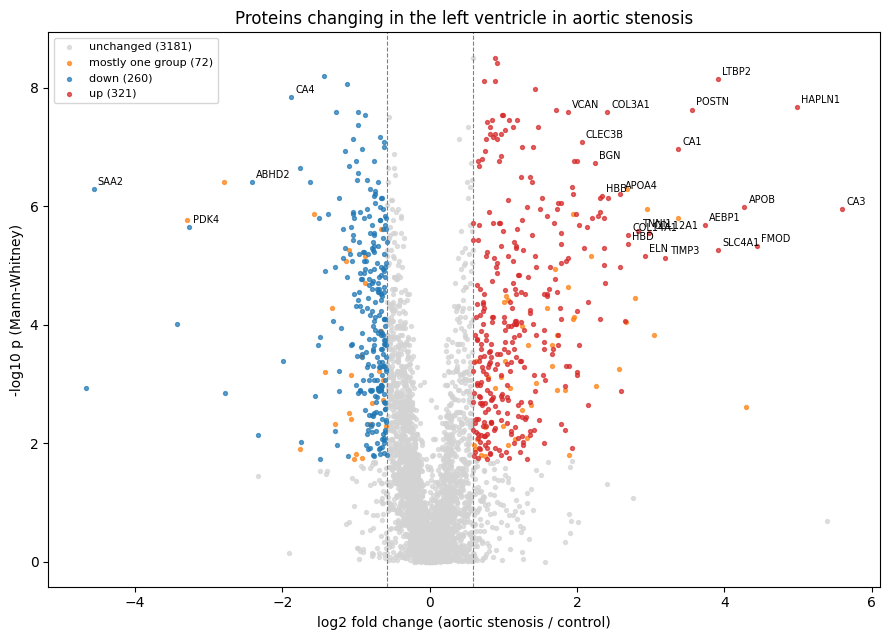

In [8]:
colors = {"up": "tab:red", "down": "tab:blue", "mostly one group": "tab:orange", "unchanged": "lightgrey"}
fig, ax = plt.subplots(figsize=(9, 6.5))
for direction in ["unchanged", "mostly one group", "down", "up"]:
    r = res[res.direction == direction]
    ax.scatter(r.log2FC, -np.log10(r.p), s=8, color=colors[direction], alpha=0.7,
               label=f"{direction} ({len(r)})")

# Label the strongest changes in the main hit list: far out on both axes
top = res[res.direction.isin(["up", "down"])].assign(score=lambda d: -np.log10(d.p) * d.log2FC.abs())
top = top.sort_values("score", ascending=False).drop_duplicates("gene")   # isoforms: label each gene once
for r in top.head(25).itertuples():
    ax.annotate(r.gene, (r.log2FC, -np.log10(r.p)), fontsize=7, xytext=(3, 3), textcoords="offset points")

ax.axvline(FC, color="grey", ls="--", lw=0.8); ax.axvline(-FC, color="grey", ls="--", lw=0.8)
ax.set(xlabel="log2 fold change (aortic stenosis / control)", ylabel="-log10 p (Mann-Whitney)",
       title="Proteins changing in the left ventricle in aortic stenosis")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/volcano_AS_vs_CON.png", dpi=200); plt.show()

## A8 · Look at the proteins measured mostly in one group

These are kept out of the enrichment, but they are not thrown away: a protein present in one group and
almost absent in the other can be the most interesting finding of all. Look at them, and think about
**why** each one might be missing. For example, acute-phase proteins (CRP, SAA1, PTX3) that are high
mainly in the donor hearts may reflect the donor's condition rather than the disease.

In [9]:
one = res[res.direction == "mostly one group"].sort_values("log2FC")
print(f"{len(one)} proteins; higher in controls: {(one.log2FC < 0).sum()}, higher in AS: {(one.log2FC > 0).sum()}\n")
one[["gene", "log2FC", "q", "valid_frac_AS", "valid_frac_CON", "protein_name"]].round(4)

72 proteins; higher in controls: 26, higher in AS: 46



,gene,log2FC,q,valid_frac_AS,valid_frac_CON,protein_name
1429,PTX3,-3.2993,0.0000,0.32,0.82,Pentraxin-related protein PTX3
1151,SAA1,-2.7937,0.0000,0.24,0.94,Serum amyloid A-1 protein;Amyloid protein A;Se...
972,CRP,-1.7622,0.0369,0.27,0.76,C-reactive protein;C-reactive protein(1-205)
257,DHRS7C,-1.5661,0.0000,0.37,0.94,Dehydrogenase/reductase SDR family member 7C
1285,ATP2A2,-1.4277,0.0035,0.39,0.71,Sarcoplasmic/endoplasmic reticulum calcium ATP...
...,...,...,...,...,...,...
465,HAPLN3,2.7826,0.0004,0.76,0.06,Hyaluronan and proteoglycan link protein 3
996,ANG,2.9558,0.0000,0.83,0.29,Angiogenin
2271,ITPR2,3.0518,0.0012,0.76,0.47,"Inositol 1,4,5-trisphosphate receptor type 2"
276,POSTN,3.3743,0.0000,0.78,0.18,NaN


## A9 · A quick check: does a Welch t-test agree?

The examiners may ask why we used a rank test and not the t-test from the in-class notebook. A simple
answer is to show that both give mostly the same proteins. Here we run the Welch t-test (as in Week 7,
on the real values only) and count how many of our hits it also finds.

In [10]:
import warnings
with warnings.catch_warnings():          # a few proteins have < 2 real values in a group: their t-test is NaN
    warnings.simplefilter("ignore")
    welch = stats.ttest_ind(not_imp[case], not_imp[ctl], axis=1, equal_var=False, nan_policy="omit")
q_welch = stats.false_discovery_control(np.nan_to_num(np.asarray(welch.pvalue, dtype=float), nan=1.0))
hits_mw    = set(res.index[res.direction.isin(["up", "down"])])
hits_welch = set(res.index[(q_welch < Q_CUT) & (res.log2FC.abs() > FC) & both_ok])
print(f"Mann-Whitney hits: {len(hits_mw)} | Welch hits: {len(hits_welch)} | in both: {len(hits_mw & hits_welch)} "
      f"({len(hits_mw & hits_welch) / len(hits_mw):.0%} of the Mann-Whitney hits)")

Mann-Whitney hits: 581 | Welch hits: 578 | in both: 542 (93% of the Mann-Whitney hits)


## A10 · The three lists enrichment needs, and saving the results

Enrichment analysis needs three lists of gene symbols:

| List | Content |
|---|---|
| `up` | proteins higher in AS (main hit list) |
| `down` | proteins lower in AS (main hit list) |
| `background` | **every protein we tested**, changed or not |

`set()` removes duplicates: a few gene symbols appear on more than one protein group (for example
different isoforms of titin), and each gene should count once.

We also save the full results table, so the network step (STRING / Cytoscape) can start from the
same numbers.

In [11]:
up         = sorted(set(res.gene[res.direction == "up"])   - {""})
down       = sorted(set(res.gene[res.direction == "down"]) - {""})
background = sorted(set(res.gene) - {""})
print(f"up: {len(up)} genes | down: {len(down)} genes | background: {len(background)} genes")

res.sort_values("q").to_csv(f"{OUT_DIR}/AS_vs_CON_results.csv", index=False)
print(f"saved {OUT_DIR}/AS_vs_CON_results.csv")

up: 311 genes | down: 259 genes | background: 3720 genes
saved results/AS_vs_CON_results.csv


---
# Part B · Enrichment analysis

## What we are doing

A list of a few hundred proteins is hard to interpret one by one. **Enrichment analysis** asks: are
proteins with a given function **over-represented** in our list, compared with what we would expect by
chance?

For every term (for example the GO term "collagen-containing extracellular matrix") the tool counts:

- how many of the **background** proteins carry the term (`term_size`)
- how many of **our hits** carry it (`intersection_size`)

and asks, with a hypergeometric test, whether the overlap is larger than chance. Because thousands of
terms are tested, the p-values are corrected for multiple testing.

**The background.** As in the in-class notebook: the background is **the proteins we measured and
tested**, not the whole genome. A mass spectrometer only sees the more abundant proteins of a tissue,
so in heart tissue the measured proteins are already rich in mitochondrial, muscle and matrix
proteins. Against the whole genome, almost any list would look "enriched" for those. B3 shows this.

**Up and down separately.** Mixing the two would blur opposing signals (for example matrix proteins
going up and metabolic proteins going down).

## B1 · Install and connect to g:Profiler

[g:Profiler](https://biit.cs.ut.ee/gprofiler/) tests a gene list against several databases at once.
We use the same four as in class:

| Source | What it is |
|---|---|
| `GO:BP` | Gene Ontology, biological process (e.g. "collagen fibril organization") |
| `GO:CC` | Gene Ontology, cellular component (e.g. "mitochondrial inner membrane") |
| `REAC` | Reactome pathways |
| `KEGG` | KEGG pathways |

Its p-values are already corrected for testing many terms (g:Profiler's own method, called g:SCS).

In [12]:
%pip install -q gprofiler-official

Note: you may need to restart the kernel to use updated packages.


## B2 · g:Profiler with our own background

This is the cell from the in-class notebook (B3), run twice: once for the up- and once for the
down-regulated proteins.

- `background=background, domain_scope="custom"` tells g:Profiler to use our tested proteins as the
  background, not the whole genome.
- `no_evidences=False` makes g:Profiler also return **which of our genes** belong to each term
  (column `intersections`). The class notebook did not ask for this; we need it to know which proteins
  to put into the network.

In [13]:
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)
SOURCES = ["GO:BP", "GO:CC", "REAC", "KEGG"]

def enrich(query, use_background=True):
    '''Run g:Profiler on a list of gene symbols. By default against OUR background.'''
    extra = dict(background=background, domain_scope="custom") if use_background else {}
    enr = gp.profile(organism="hsapiens", query=query, sources=SOURCES, no_evidences=False, **extra)
    if "intersections" in enr.columns:                      # list of genes -> one readable string
        enr["genes"] = enr["intersections"].apply(lambda g: ", ".join(g) if isinstance(g, list) else str(g))
    return enr

enr_up   = enrich(up)
enr_down = enrich(down)
print(f"{len(up)} up-regulated genes   -> {len(enr_up)} enriched terms")
print(f"{len(down)} down-regulated genes -> {len(enr_down)} enriched terms")

COLS = ["source", "name", "p_value", "intersection_size", "term_size"]
enr_up[COLS].head(15)

311 up-regulated genes   -> 111 enriched terms
259 down-regulated genes -> 2 enriched terms


,source,name,p_value,intersection_size,term_size
0,GO:CC,blood microparticle,4.458367e-30,54,96
1,GO:CC,extracellular matrix,1.753044e-26,51,96
2,GO:CC,external encapsulating structure,1.753044e-26,51,96
3,KEGG,Complement and coagulation cascades,3.249804e-23,35,49
4,GO:CC,extracellular region,1.932077e-20,191,1271
5,GO:CC,extracellular space,1.028139e-18,178,1165
6,REAC,Extracellular matrix organization,1.370935e-16,46,116
7,REAC,Complement cascade,1.193288e-15,28,44
8,REAC,Regulation of Complement cascade,3.971278e-15,27,42
9,GO:CC,cell periphery,6.168740e-15,163,1086


The table above is for the **up**-regulated proteins. How to read it:

- `p_value`: corrected p-value. Smaller is more significant.
- `term_size`: how many of our background proteins carry the term.
- `intersection_size`: how many of our hits carry it.

A term with a large `term_size` and a small `intersection_size` can still be significant, but it says
less. Look for specific terms where a good share of the term is in your list.

Next, the same table for the **down**-regulated proteins:

In [14]:
enr_down[COLS].head(15)

,source,name,p_value,intersection_size,term_size
0,REAC,Translation,0.002932,39,234
1,GO:CC,mitochondrion,0.012604,98,925


### Plot the top terms

Same plot as in class: the 15 most significant terms, coloured by database. Longer bars are more
significant. Up and down side by side.

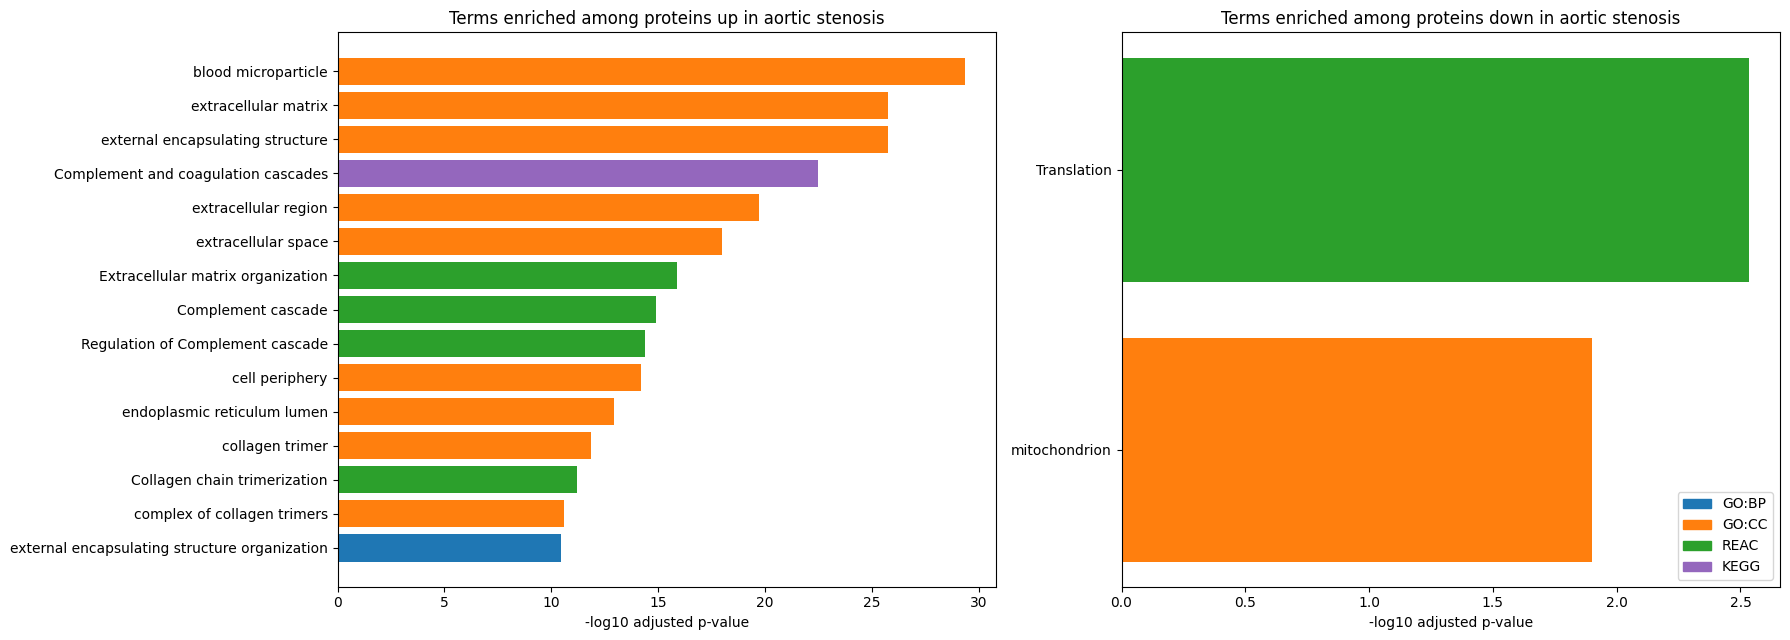

In [15]:
from matplotlib.patches import Patch
palette = {"GO:BP": "tab:blue", "GO:CC": "tab:orange", "REAC": "tab:green", "KEGG": "tab:purple"}

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, enr, label in [(axes[0], enr_up, "up"), (axes[1], enr_down, "down")]:
    top_terms = enr.head(15).iloc[::-1]                      # reverse so the best is on top
    ax.barh(top_terms["name"].str[:55], -np.log10(top_terms["p_value"]), color=top_terms["source"].map(palette))
    ax.set(xlabel="-log10 adjusted p-value", title=f"Terms enriched among proteins {label} in aortic stenosis")
axes[1].legend(handles=[Patch(color=c, label=s) for s, c in palette.items()], loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gprofiler_top_terms.png", dpi=200); plt.show()

### Save the results

Two CSV files with every enriched term, including the genes behind each term (`genes` column). These
are what you choose the terms for the presentation from, and the `genes` column of a term is the
protein list for the network step.

In [16]:
keep_cols = [c for c in ["source", "native", "name", "p_value", "term_size", "intersection_size", "genes"] if c in enr_up.columns]
enr_up[keep_cols].to_csv(f"{OUT_DIR}/gprofiler_up.csv", index=False)
enr_down[keep_cols].to_csv(f"{OUT_DIR}/gprofiler_down.csv", index=False)
print(f"saved {OUT_DIR}/gprofiler_up.csv and {OUT_DIR}/gprofiler_down.csv")

saved results/gprofiler_up.csv and results/gprofiler_down.csv


## B3 · Why the background matters: the same test against the whole genome

The in-class notebook repeats the analysis the way it is often (wrongly) done: against **the whole
genome** as background. We do the same for the up-regulated proteins.

Compare the result with B2. You should get many more terms, and more general ones ("extracellular
space", "cytoplasm"...), because against the whole genome any protein that a mass spectrometer can
detect in heart tissue looks special. This comparison is good material for the "what the technology
can and cannot see" part of the presentation.

In [17]:
enr_up_genome = enrich(up, use_background=False)
print(f"up-regulated genes against OUR background:      {len(enr_up)} enriched terms")
print(f"up-regulated genes against the WHOLE GENOME:    {len(enr_up_genome)} enriched terms\n")
enr_up_genome[COLS].head(10)

up-regulated genes against OUR background:      111 enriched terms
up-regulated genes against the WHOLE GENOME:    380 enriched terms



,source,name,p_value,intersection_size,term_size
0,GO:CC,extracellular space,1.028792e-69,178,3252
1,GO:CC,extracellular vesicle,6.500688e-64,144,2141
2,GO:CC,extracellular organelle,6.915345e-64,144,2142
3,GO:CC,extracellular membrane-bounded organelle,6.915345e-64,144,2142
4,GO:CC,blood microparticle,8.343276e-63,54,138
5,GO:CC,extracellular exosome,8.508780e-63,142,2111
6,GO:CC,extracellular region,2.244711e-62,191,4249
7,GO:CC,vesicle,4.566297e-43,163,4032
8,GO:CC,extracellular matrix,8.858171e-36,51,339
9,GO:CC,external encapsulating structure,1.030490e-35,51,340


## B4 · Pathways with Reactome

[Reactome](https://reactome.org) is a curated database of human pathways, drawn as diagrams of
molecular reactions. Its analysis service takes a gene list and returns the over-represented
pathways. It also gives a **link to the Reactome Pathway Browser**, where you can see your proteins
drawn on the pathway diagrams.

This is the cell from the in-class notebook (B4), again run for up and down separately.

Two things to keep in mind:

- Reactome's service compares against **all of Reactome**, not against our measured proteins, so read
  it together with the g:Profiler result above (which also contains Reactome pathways, `REAC`, tested
  against our own background).
- The links stop working after about a week. Open them, and download what you need (diagram images:
  *Export* in the diagram panel; tables: *Downloads* in the Analysis tab).

In [18]:
import requests

def reactome(gene_list):
    '''Send a gene list to the Reactome analysis service; return the top pathways and a browser link.'''
    url = "https://reactome.org/AnalysisService/identifiers/projection?pageSize=15&page=1&interactors=false"
    reply = requests.post(url, data="\n".join(gene_list),          # one gene per line
                          headers={"Content-Type": "text/plain"}, timeout=120).json()
    paths = pd.DataFrame([{"pathway": p["name"],
                           "FDR": p["entities"]["fdr"],                # corrected for testing many pathways
                           "found": p["entities"]["found"],            # our proteins in the pathway
                           "pathway size": p["entities"]["total"]}
                          for p in reply["pathways"]])
    link = f"https://reactome.org/PathwayBrowser/#/DTAB=AN&ANALYSIS={reply['summary']['token']}"
    return paths, link

paths_up, link_up     = reactome(up)
paths_down, link_down = reactome(down)
print("Open the results in Reactome's Pathway Browser (links work for about a week):")
print("  up in AS:  ", link_up)
print("  down in AS:", link_down)
paths_up.to_csv(f"{OUT_DIR}/reactome_up.csv", index=False)
paths_down.to_csv(f"{OUT_DIR}/reactome_down.csv", index=False)
paths_up.head(10)

Open the results in Reactome's Pathway Browser (links work for about a week):
  up in AS:   https://reactome.org/PathwayBrowser/#/DTAB=AN&ANALYSIS=MjAyNjExMTkxMDUzMTBfMzkx
  down in AS: https://reactome.org/PathwayBrowser/#/DTAB=AN&ANALYSIS=MjAyNjExMTkxMDUzMTFfMzky


,pathway,FDR,found,pathway size
0,Regulation of Complement cascade,9.325873e-15,31,148
1,Complement cascade,9.325873e-15,32,172
2,Assembly of collagen fibrils and other multime...,9.325873e-15,22,67
3,Collagen degradation,9.325873e-15,21,69
4,ECM proteoglycans,9.325873e-15,27,79
5,Extracellular matrix organization,9.325873e-15,49,351
6,Collagen chain trimerization,9.325873e-15,21,44
7,Platelet degranulation,9.325873e-15,28,140
8,Integrin cell surface interactions,9.325873e-15,25,86
9,Response to elevated platelet cytosolic Ca2+,9.325873e-15,28,147


In [19]:
paths_down.head(10)

,pathway,FDR,found,pathway size
0,Translation,1.123546e-13,46,423
1,Cap-dependent Translation Initiation,8.605339e-13,23,130
2,Eukaryotic Translation Initiation,8.605339e-13,23,130
3,GTP hydrolysis and joining of the 60S ribosoma...,1.054046e-12,22,120
4,L13a-mediated translational silencing of Cerul...,1.054046e-12,22,120
5,Cotranslational targeting of proteins to the e...,1.417533e-12,25,169
6,Formation of a pool of free 40S subunits,7.929657e-12,20,106
7,Nonsense Mediated Decay (NMD) independent of t...,3.151679e-11,19,101
8,Eukaryotic Translation Elongation,3.320011e-11,19,102
9,Peptide chain elongation,1.356019e-10,18,97


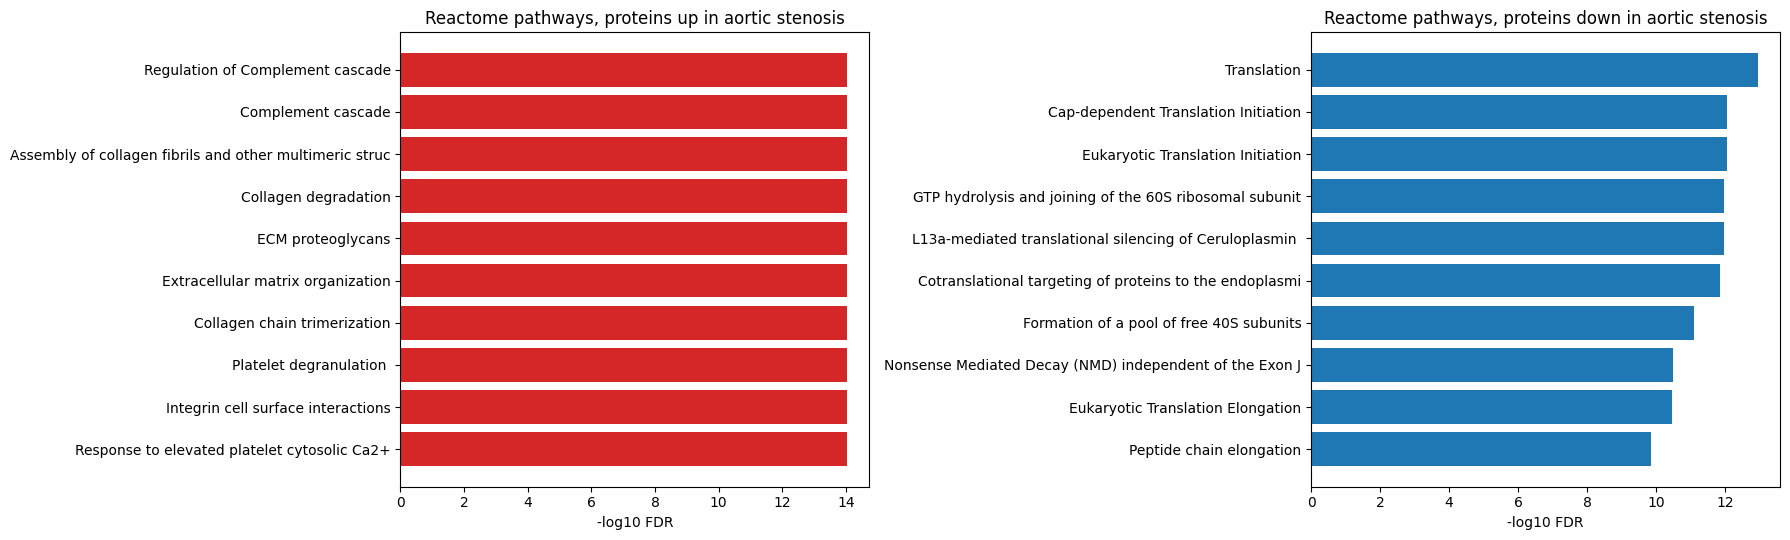

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, paths, label, col in [(axes[0], paths_up, "up", "tab:red"), (axes[1], paths_down, "down", "tab:blue")]:
    top_p = paths.head(10).iloc[::-1]
    ax.barh(top_p["pathway"].str[:55], -np.log10(top_p["FDR"]), color=col)
    ax.set(xlabel="-log10 FDR", title=f"Reactome pathways, proteins {label} in aortic stenosis")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/reactome_top_pathways.png", dpi=200); plt.show()

---
# What to do with the results

1. **Pick the story.** From each direction, choose 3–5 specific terms that are not just repeats of each
   other (GO terms are a hierarchy, so a term, its parent and its grandparent often all come out
   significant). Prefer specific terms with a reasonable `intersection_size`.
2. **Separate finding from interpretation.** "Fatty-acid oxidation proteins are over-represented among
   proteins lower in AS" is what we found. "The heart switches its fuel" is what we suggest.
3. **Network step.** Take the `genes` of one or two key terms from `gprofiler_up.csv` /
   `gprofiler_down.csv`, put them into STRING, and colour the nodes in Cytoscape by `log2FC` from
   `AS_vs_CON_results.csv` (Week 3).

## Choices in this notebook we must be able to defend

| Choice | Why | What it costs |
|---|---|---|
| Mann–Whitney test | many proteins not normally distributed (QC notebook, section 15) | slightly less power than a t-test; A9 shows how much the two agree |
| Test on imputed data, fold change on real data | the test needs a complete table; imputed values would inflate fold changes | proteins with many imputed values are less reliable |
| `MIN_VALID_BOTH` = 50 % | keeps "present in one group only" proteins from dominating the hit list | those proteins are reported separately, not enriched |
| q < 0.05 and 1.5-fold | conventional cutoffs, same as in class | the hit list, and therefore the enrichment, depend on them: try 2-fold and see what survives |
| Measured proteins as background | the mass spectrometer only sees abundant proteins | none; the whole-genome background would be wrong (B3) |
| First gene symbol per protein group | enrichment needs one symbol per protein | protein groups with several genes are represented by one |
| Donor hearts as controls | the only healthy left-ventricle tissue available | differences in how the tissue was obtained, and in age, cannot be separated from the disease |